In [13]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ----------- ---------------------------- 2.4/8.0 MB 12.5 MB/s eta 0:00:01
   -------------------------- ------------- 5.2/8.0 MB 12.5 MB/s eta 0:00:01
   -------------------------------------- - 7.6/8.0 MB 12.3 MB/s eta 0:00:01
   ---------------------------------------- 8.0/8.0 MB 11.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LassoCV, RidgeCV, LogisticRegressionCV, lasso_path
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import roc_curve, auc, accuracy_score

sns.set_theme(style="darkgrid")

higgs_data = fetch_openml(name='higgs', version=1, as_frame=True)
df = higgs_data.frame.dropna()
df

,class,lepton_pT,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet1pt,jet1eta,jet1phi,jet1b-tag,...,jet4eta,jet4phi,jet4b-tag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,1,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,...,-1.138930,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343
1,1,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,...,1.128848,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118
2,0,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,...,-0.678379,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904
3,1,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,...,-0.373566,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487
4,0,1.595839,-0.607811,0.007075,1.818450,-0.111906,0.847550,-0.566437,1.581239,2.173076,...,-0.654227,-1.274345,3.101961,0.823761,0.938191,0.971758,0.789176,0.430553,0.961357,0.957818
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98044,0,2.786130,-0.679884,-1.673151,0.854033,1.020573,0.844252,-0.323831,-0.132437,0.000000,...,-0.807466,1.054172,0.000000,0.931880,0.880436,1.399047,1.041965,0.875924,1.056742,1.383591
98045,1,0.908091,-0.825006,-0.830871,0.736298,1.512713,0.881811,-0.363440,0.006813,1.086538,...,-0.187013,0.716785,0.000000,1.317681,1.010795,0.985962,0.957878,1.454672,0.903937,0.786069
98046,0,2.512898,0.530759,-1.470626,1.641798,1.613386,0.934027,1.521958,-0.049836,0.000000,...,0.053673,-0.386483,0.000000,0.774413,0.745263,0.997088,1.392387,0.864681,1.179783,1.086167
98047,0,0.903699,0.261943,-0.429149,1.892855,0.313687,0.493396,-1.494282,-1.458506,0.000000,...,-0.283621,1.110772,3.101961,0.527038,0.607263,1.125286,0.634106,0.115543,0.425828,0.692506


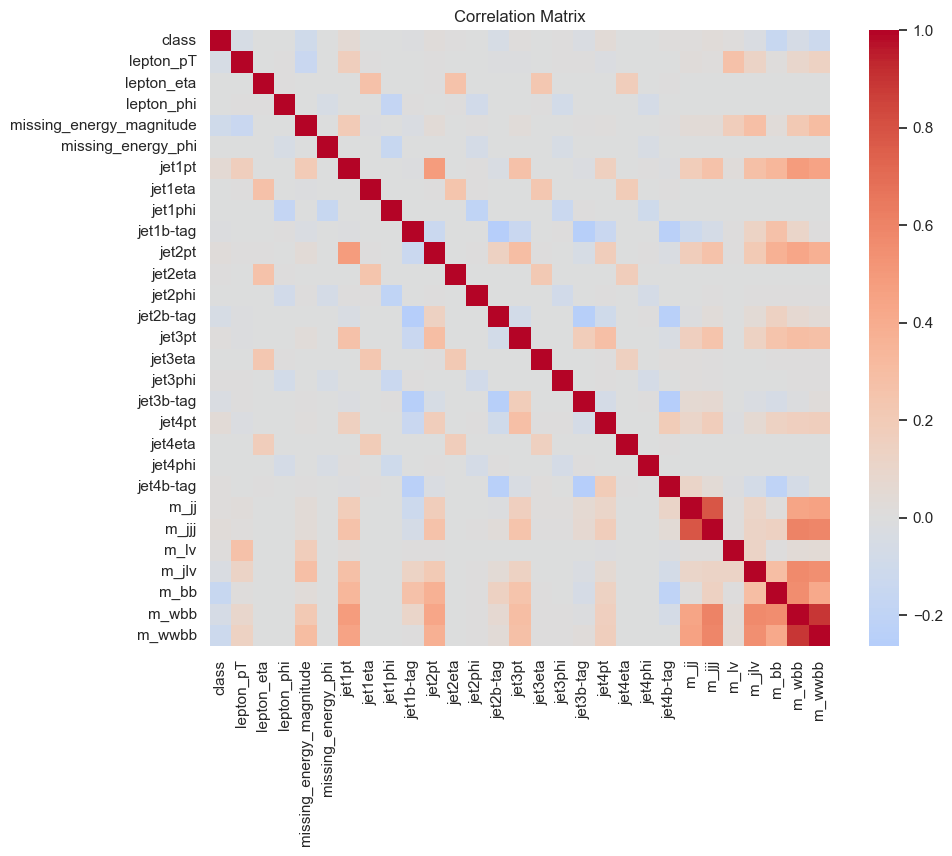

In [7]:
corr = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

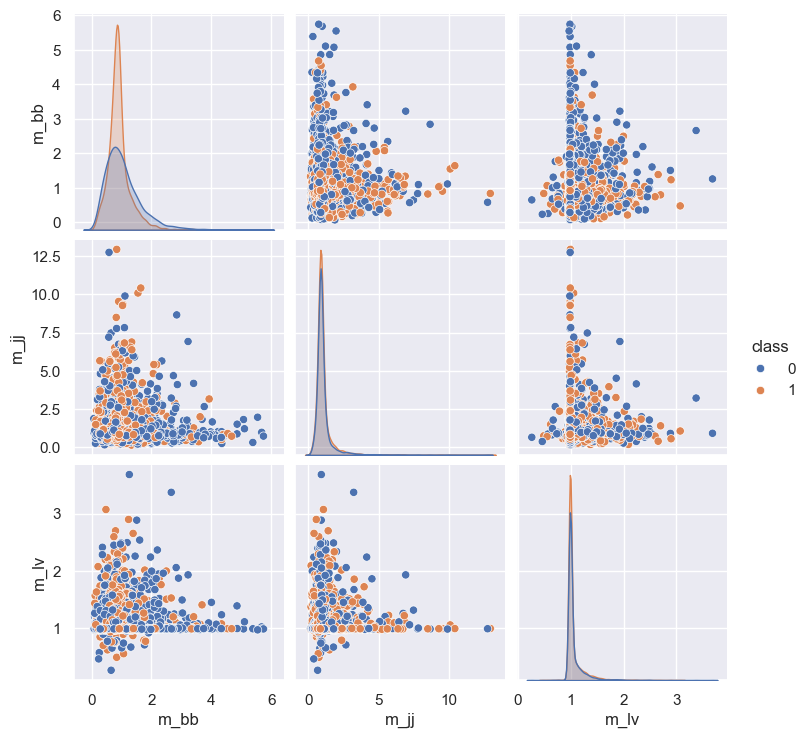

In [8]:
df_sample = df.sample(frac=0.1, random_state=42)  # 10% of data

sns.pairplot(df_sample[["m_bb", "m_jj", "m_lv", 'class']],
             hue='class')
plt.show()

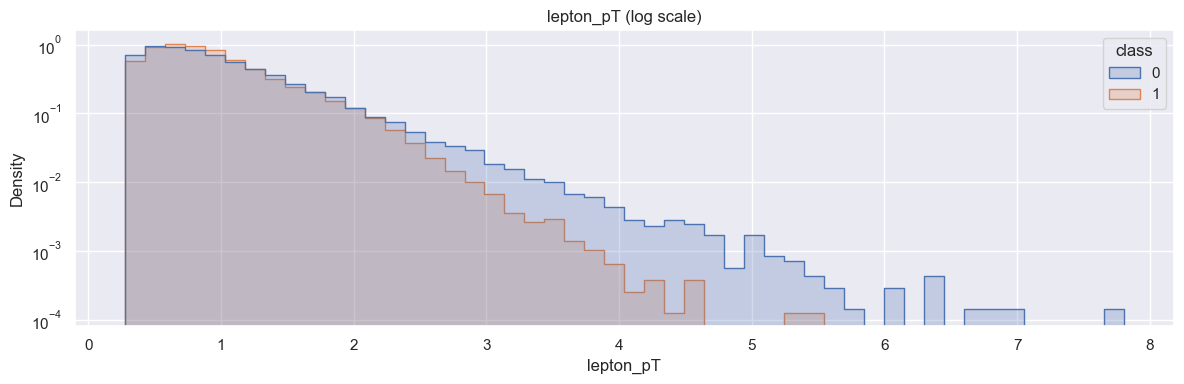

In [9]:
#features = [col for col in df.columns if col != 'class']
features = ["lepton_pT"]

for col in features:
    plt.figure(figsize=(12, 4))
    
    sns.histplot(
        data=df,
        x=col,
        hue='class',
        bins=50,
        stat='density',
        common_norm=False,
        element='step'  # stile più pulito tipo ROOT
    )
    
    plt.yscale('log')
    plt.title(f'{col} (log scale)')
    plt.tight_layout()
    plt.show()

In [10]:
# DATA PREPARATION

# Separation between features (X) and target (y)
X = df.drop(columns=['class'])
y = df['class'].astype(int)
feature_names = X.columns.tolist()

# Scaler (even if data appears to be already scaled)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- FIX: Train/Test split to avoid data leakage in evaluation ---
# Models are trained on X_train, evaluated on X_test (never seen before)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train size: {X_train.shape[0]} samples | Test size: {X_test.shape[0]} samples")


Train size: 78439 samples | Test size: 19610 samples


PCA reduces from 28 to 20 components keeping 90% of the variance.

PCA Component 1 explains 14.87% of variance

                     Feature   Loading  Abs_Loading
26                     m_wbb  0.450865     0.450865
27                    m_wwbb  0.434634     0.434634
22                     m_jjj  0.334953     0.334953
5                     jet1pt  0.308693     0.308693
9                     jet2pt  0.286556     0.286556
24                     m_jlv  0.280143     0.280143
25                      m_bb  0.272876     0.272876
21                      m_jj  0.270919     0.270919
13                    jet3pt  0.220926     0.220926
17                    jet4pt  0.139093     0.139093
3   missing_energy_magnitude  0.131163     0.131163
0                  lepton_pT  0.059247     0.059247
23                      m_lv  0.037837     0.037837
12                 jet2b-tag  0.031859     0.031859
20                 jet4b-tag -0.019599     0.019599
16                 jet3b-tag  0.010197     0.010197
11  

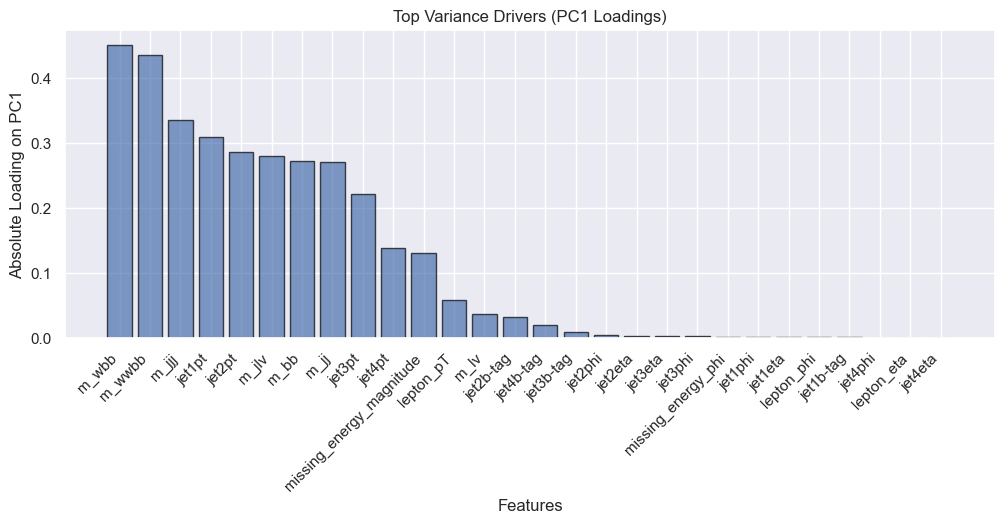

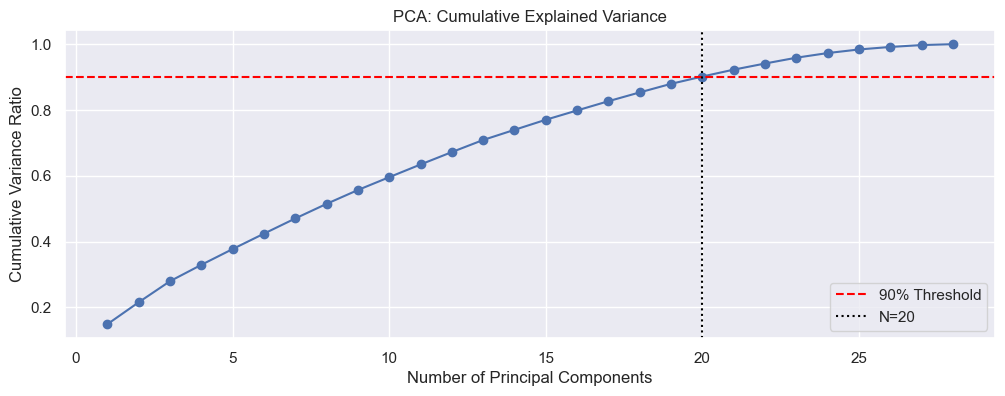

In [11]:
# MODEL 1: UNSUPERVISED PCA (90% variance)

# Choose right number of components for the PCA
pca_full = PCA().fit(X_scaled) #evaluate all
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_) #check weights
N_COMPONENTS = np.where(cumulative_variance >= 0.90)[0][0] + 1 #choose only >= 90% of variance
print(f"PCA reduces from {len(feature_names)} to {N_COMPONENTS} components keeping 90% of the variance.")

# Run PCA
pca = PCA(n_components=N_COMPONENTS)
X_pca = pca.fit_transform(X_scaled)

# Graphic evaluation
loadings = pca.components_[0]
pca_analysis = pd.DataFrame({
    'Feature': feature_names,
    'Loading': loadings,
    'Abs_Loading': np.abs(loadings)
}).sort_values('Abs_Loading', ascending=False)

explained_variance_ratio = pca.explained_variance_ratio_
print(f"\nPCA Component 1 explains {explained_variance_ratio[0]:.2%} of variance\n")
print(pca_analysis)

plt.figure(figsize=(12, 4))
plt.bar(pca_analysis['Feature'], pca_analysis['Abs_Loading'], alpha=0.7, edgecolor='black')
plt.xlabel('Features')
plt.ylabel('Absolute Loading on PC1')
plt.title('Top Variance Drivers (PC1 Loadings)')
plt.xticks(rotation=45, ha='right')
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.axhline(y=0.9, color='red', linestyle='--', label='90% Threshold')
plt.axvline(x=N_COMPONENTS, color='black', linestyle=':', label=f'N={N_COMPONENTS}')
plt.title("PCA: Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Variance Ratio")
plt.legend()
plt.show()

# Note: automated method
# pca = PCA(n_components=0.9)
# X_pca = pca.fit_transform(X_scaled)

Best alpha found: 0.00034 with mean MSE: 0.22558
Lasso eliminated 2 features over 28
                     Feature  Coefficient  Abs_Coefficient      Status
27                    m_wwbb    -0.193908         0.193908        Kept
26                     m_wbb     0.133573         0.133573        Kept
25                      m_bb    -0.124931         0.124931        Kept
5                     jet1pt     0.070380         0.070380        Kept
22                     m_jjj     0.051683         0.051683        Kept
3   missing_energy_magnitude    -0.050139         0.050139        Kept
24                     m_jlv     0.040011         0.040011        Kept
0                  lepton_pT    -0.039469         0.039469        Kept
21                      m_jj    -0.022793         0.022793        Kept
23                      m_lv     0.022615         0.022615        Kept
17                    jet4pt     0.020856         0.020856        Kept
16                 jet3b-tag    -0.020438         0.020438     

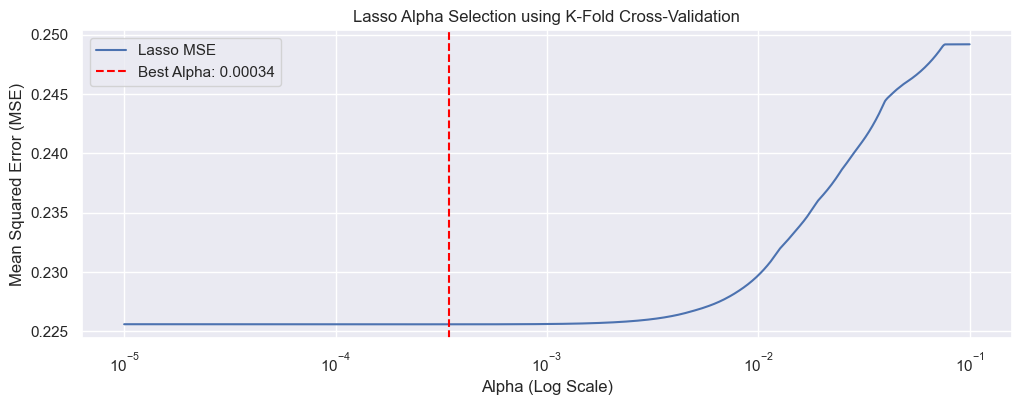

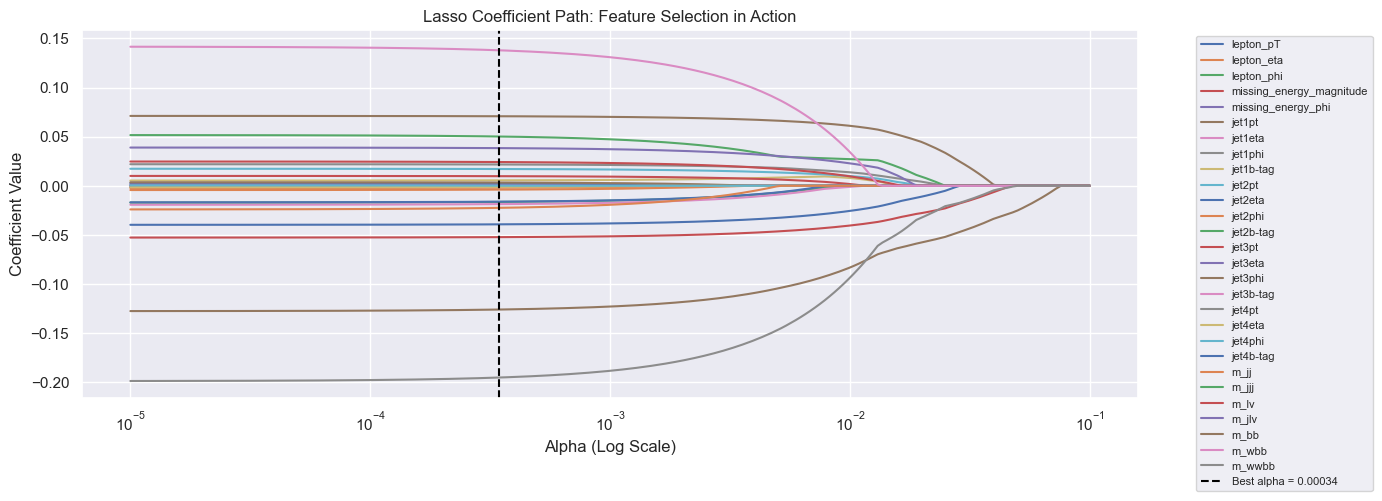

Features elimination threshold:
  jet1phi                        eliminated at alpha ~ 0.000048
  missing_energy_phi             eliminated at alpha ~ 0.000255
  jet4phi                        eliminated at alpha ~ 0.000445
  jet1eta                        eliminated at alpha ~ 0.000891
  jet3eta                        eliminated at alpha ~ 0.001023
  lepton_phi                     eliminated at alpha ~ 0.001351
  jet4eta                        eliminated at alpha ~ 0.001351
  jet2eta                        eliminated at alpha ~ 0.001956
  jet2phi                        eliminated at alpha ~ 0.002248
  lepton_eta                     eliminated at alpha ~ 0.003740
  jet3phi                        eliminated at alpha ~ 0.003917
  m_jj                           eliminated at alpha ~ 0.005171
  jet4b-tag                      eliminated at alpha ~ 0.008214
  jet2b-tag                      eliminated at alpha ~ 0.010353
  jet3b-tag                      eliminated at alpha ~ 0.011357
  jet3pt

In [12]:
# MODEL 2: SUPERVISED LASSO L1

# Initialize KFold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

alphas_lasso = np.logspace(-5, -1, 1000) # From 0.00001 to 0.1
# NOTE: fit on X_train only to avoid data leakage
lasso_cv = LassoCV(alphas=alphas_lasso, cv=kf, max_iter=10000, n_jobs=-1).fit(X_train, y_train)

lasso_mse_mean = np.mean(lasso_cv.mse_path_, axis=1)
lasso_best_mse_index = np.argmin(lasso_mse_mean)
lasso_best_mse = lasso_mse_mean[lasso_best_mse_index]
print(f"Best alpha found: {lasso_cv.alpha_:.5f} with mean MSE: {lasso_best_mse:.5f}")

lasso_coefs = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lasso_cv.coef_,
    'Abs_Coefficient': np.abs(lasso_cv.coef_),
    'Status': np.where(lasso_cv.coef_ == 0, 'Eliminated', 'Kept')
}).sort_values('Abs_Coefficient', ascending=False)
print(f"Lasso eliminated {(lasso_coefs['Coefficient'] == 0).sum()} features over {len(feature_names)}")
print(lasso_coefs)

plt.figure(figsize=(12, 4))
plt.semilogx(lasso_cv.alphas_, lasso_mse_mean, label='Lasso MSE')
plt.axvline(lasso_cv.alpha_, color='red', linestyle='--', label=f'Best Alpha: {lasso_cv.alpha_:.5f}')
plt.xlabel('Alpha (Log Scale)')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Lasso Alpha Selection using K-Fold Cross-Validation')
plt.legend()
plt.show()

# LASSO COEFFICIENT PATH: shows how each feature coefficient shrinks to zero as alpha increases

alphas_path, coefs_path, _ = lasso_path(X_train, y_train,
                                         alphas=np.logspace(-5, -1, 200),
                                         max_iter=10000)

plt.figure(figsize=(14, 5))
for i, name in enumerate(feature_names):
    plt.semilogx(alphas_path, coefs_path[i], label=name, linewidth=1.5)

plt.axvline(lasso_cv.alpha_, color='black', linestyle='--', linewidth=1.5,
            label=f'Best alpha = {lasso_cv.alpha_:.5f}')
plt.xlabel('Alpha (Log Scale)')
plt.ylabel('Coefficient Value')
plt.title('Lasso Coefficient Path: Feature Selection in Action')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

# Show order in which features get eliminated as alpha increases
# Invertiamo i path in modo che alpha cresca (da 1e-5 a 1e-1)
alphas_increasing = alphas_path[::-1]
coefs_increasing = coefs_path[:, ::-1]

print("Features elimination threshold:")
elimination_order = []

for i, name in enumerate(feature_names):
    # Cerchiamo gli indici in cui il coefficiente è ~0
    # Guardiamo l'array da alpha piccolo a alpha grande
    zero_indices = np.where(np.abs(coefs_increasing[i]) <= 1e-4)[0]
    
    if len(zero_indices) > 0:
        # Il primo momento (l'alpha più basso) in cui il coefficiente diventa zero
        first_zero_idx = zero_indices[0]
        elimination_alpha = alphas_increasing[first_zero_idx]
        elimination_order.append((name, elimination_alpha))
    else:
        # Se non diventa mai zero, resiste oltre l'alpha massimo testato
        elimination_order.append((name, float('inf')))

# Ordiniamo in base all'alpha in cui muoiono (dal più piccolo al più grande)
for name, alpha_elim in sorted(elimination_order, key=lambda x: x[1]):
    if alpha_elim == float('inf'):
        print(f"  {name:30s} survives beyond max alpha ({alphas_increasing[-1]:.5f})")
    else:
        print(f"  {name:30s} eliminated at alpha ~ {alpha_elim:.6f}")

In [13]:
# MODEL 3: SUPERVISED RIDGE L2

alphas_ridge = np.logspace(-1, 2, 100) # From 0.1 to 100
# NOTE: fit on X_train only to avoid data leakage
ridge_cv = RidgeCV(alphas=alphas_ridge, cv=kf).fit(X_train, y_train)
print(f"Best alpha for Ridge: {ridge_cv.alpha_:.5f}")

ridge_coefs = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': ridge_cv.coef_,
    'Abs_Coefficient': np.abs(ridge_cv.coef_)
}).sort_values('Abs_Coefficient', ascending=False)
print(ridge_coefs)


Best alpha for Ridge: 40.37017
                     Feature  Coefficient  Abs_Coefficient
27                    m_wwbb    -0.196551         0.196551
26                     m_wbb     0.136200         0.136200
25                      m_bb    -0.126259         0.126259
5                     jet1pt     0.070679         0.070679
22                     m_jjj     0.053128         0.053128
3   missing_energy_magnitude    -0.050601         0.050601
24                     m_jlv     0.040590         0.040590
0                  lepton_pT    -0.039967         0.039967
21                      m_jj    -0.024328         0.024328
23                      m_lv     0.023123         0.023123
16                 jet3b-tag    -0.021138         0.021138
17                    jet4pt     0.021089         0.021089
9                     jet2pt     0.017174         0.017174
12                 jet2b-tag    -0.016934         0.016934
20                 jet4b-tag    -0.016901         0.016901
13                    jet

Lasso accuracy: 0.6361  (AUC: 0.6777 -> Poor)
Ridge accuracy: 0.6359  (AUC: 0.6778 -> Poor)


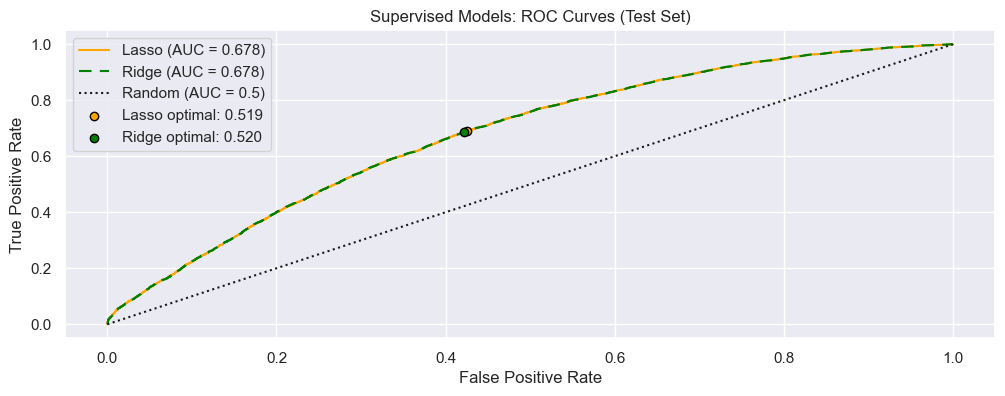

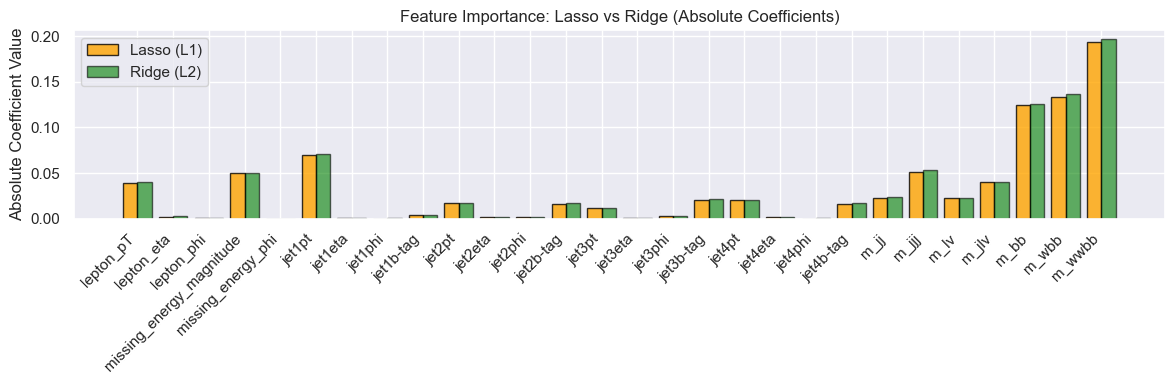

In [14]:
# PERFORMANCE ANALYSIS (evaluated on test set — no data leakage)

lasso_scores = lasso_cv.predict(X_test)
ridge_scores = ridge_cv.predict(X_test)

# ROC Curves
fpr_l, tpr_l, thresh_l = roc_curve(y_test, lasso_scores)
auc_lasso = auc(fpr_l, tpr_l)
opt_idx_l = np.argmax(tpr_l - fpr_l)  # Youden's J statistic

fpr_r, tpr_r, thresh_r = roc_curve(y_test, ridge_scores)
auc_ridge = auc(fpr_r, tpr_r)
opt_idx_r = np.argmax(tpr_r - fpr_r)  # Youden's J statistic

# Accuracy at optimal threshold
lasso_preds = (lasso_scores > thresh_l[opt_idx_l]).astype(int)
ridge_preds = (ridge_scores > thresh_r[opt_idx_r]).astype(int)
def auc_label(a):
    if a >= 0.9:   return 'Excellent'
    if a >= 0.7:   return 'Good'
    if a >= 0.5:   return 'Poor'
    return 'Worse than random'
print(f"Lasso accuracy: {accuracy_score(y_test, lasso_preds):.4f}  (AUC: {auc_lasso:.4f} -> {auc_label(auc_lasso)})")
print(f"Ridge accuracy: {accuracy_score(y_test, ridge_preds):.4f}  (AUC: {auc_ridge:.4f} -> {auc_label(auc_ridge)})")

# ROC Curves Plot
plt.figure(figsize=(12, 4))
plt.plot(fpr_l, tpr_l, label=f'Lasso (AUC = {auc_lasso:.3f})', color='orange', linestyle='-')
plt.plot(fpr_r, tpr_r, label=f'Ridge (AUC = {auc_ridge:.3f})', color='green', linestyle=(0, (6, 4)))
plt.plot([0, 1], [0, 1], 'k:', label='Random (AUC = 0.5)')
plt.scatter(fpr_l[opt_idx_l], tpr_l[opt_idx_l], color='orange', marker='o',
            zorder=5, edgecolors='black', label=f'Lasso optimal: {thresh_l[opt_idx_l]:.3f}')
plt.scatter(fpr_r[opt_idx_r], tpr_r[opt_idx_r], color='green', marker='o',
            zorder=5, edgecolors='black', label=f'Ridge optimal: {thresh_r[opt_idx_r]:.3f}')
plt.title("Supervised Models: ROC Curves (Test Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()
# Coefficient Weights (Lasso vs Ridge) Plot
x_axis = np.arange(len(feature_names))
plt.figure(figsize=(12, 4))
plt.bar(x_axis - 0.2, np.abs(lasso_cv.coef_), width=0.4, label='Lasso (L1)', color='orange', alpha=0.8, edgecolor='black')
plt.bar(x_axis + 0.2, np.abs(ridge_cv.coef_), width=0.4, label='Ridge (L2)', color='green', alpha=0.6, edgecolor='black')
plt.xticks(x_axis, feature_names, rotation=45, ha='right')
plt.title("Feature Importance: Lasso vs Ridge (Absolute Coefficients)")
plt.ylabel("Absolute Coefficient Value")
plt.legend()
plt.tight_layout()
plt.show()


Best C for Logistic L1: 0.49417  (alpha = 2.02359)
Best C for Logistic L2: 0.65513  (alpha = 1.52642)
Logistic L1 accuracy: 0.6372  (AUC: 0.6785 -> Poor)
Logistic L2 accuracy: 0.6373  (AUC: 0.6785 -> Poor)


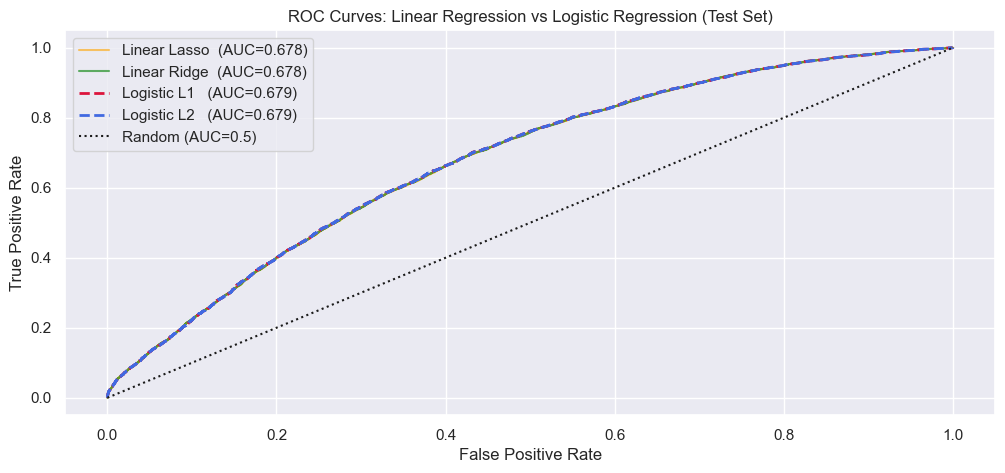

Logistic L1 eliminated 0 features over 28
                     Feature  Coefficient  Abs_Coefficient Status
27                    m_wwbb    -1.021995         1.021995   Kept
26                     m_wbb     0.688168         0.688168   Kept
25                      m_bb    -0.607909         0.607909   Kept
5                     jet1pt     0.339931         0.339931   Kept
22                     m_jjj     0.268699         0.268699   Kept
3   missing_energy_magnitude    -0.230453         0.230453   Kept
24                     m_jlv     0.212316         0.212316   Kept
0                  lepton_pT    -0.181929         0.181929   Kept
21                      m_jj    -0.107271         0.107271   Kept
23                      m_lv     0.105661         0.105661   Kept
17                    jet4pt     0.102206         0.102206   Kept
16                 jet3b-tag    -0.090813         0.090813   Kept
9                     jet2pt     0.085847         0.085847   Kept
20                 jet4b-tag    -0

In [15]:
# LOGISTIC REGRESSION with L1 (Lasso) and L2 (Ridge) penalty
# This is the correct approach for binary classification

Cs = np.logspace(-3, 3, 50)  # C = 1/alpha in sklearn convention
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# L1 Logistic (equivalent to Lasso but with log-loss)
logistic_l1 = LogisticRegressionCV(
    Cs=Cs, cv=kf, penalty='l1', solver='saga',
    max_iter=5000, random_state=42, n_jobs=-1
).fit(X_train, y_train)

# L2 Logistic (equivalent to Ridge but with log-loss)
logistic_l2 = LogisticRegressionCV(
    Cs=Cs, cv=kf, penalty='l2', solver='lbfgs',
    max_iter=5000, random_state=42, n_jobs=-1
).fit(X_train, y_train)

print(f"Best C for Logistic L1: {logistic_l1.C_[0]:.5f}  (alpha = {1/logistic_l1.C_[0]:.5f})")
print(f"Best C for Logistic L2: {logistic_l2.C_[0]:.5f}  (alpha = {1/logistic_l2.C_[0]:.5f})")

# Predict probabilities on test set
scores_l1 = logistic_l1.predict_proba(X_test)[:, 1]
scores_l2 = logistic_l2.predict_proba(X_test)[:, 1]

fpr_l1, tpr_l1, _ = roc_curve(y_test, scores_l1)
fpr_l2, tpr_l2, _ = roc_curve(y_test, scores_l2)
auc_l1 = auc(fpr_l1, tpr_l1)
auc_l2 = auc(fpr_l2, tpr_l2)

acc_l1 = accuracy_score(y_test, logistic_l1.predict(X_test))
acc_l2 = accuracy_score(y_test, logistic_l2.predict(X_test))
print(f"Logistic L1 accuracy: {acc_l1:.4f}  (AUC: {auc_l1:.4f} -> {auc_label(auc_l1)})")
print(f"Logistic L2 accuracy: {acc_l2:.4f}  (AUC: {auc_l2:.4f} -> {auc_label(auc_l2)})")

# ROC comparison: linear regression vs logistic regression
plt.figure(figsize=(12, 5))
plt.plot(fpr_l,  tpr_l,  label=f'Linear Lasso  (AUC={auc_lasso:.3f})', color='orange', linestyle='-', alpha=0.6)
plt.plot(fpr_r,  tpr_r,  label=f'Linear Ridge  (AUC={auc_ridge:.3f})', color='green',  linestyle='-', alpha=0.6)
plt.plot(fpr_l1, tpr_l1, label=f'Logistic L1   (AUC={auc_l1:.3f})',    color='crimson', linestyle='--', linewidth=2)
plt.plot(fpr_l2, tpr_l2, label=f'Logistic L2   (AUC={auc_l2:.3f})',    color='royalblue', linestyle='--', linewidth=2)
plt.plot([0, 1], [0, 1], 'k:', label='Random (AUC=0.5)')
plt.title("ROC Curves: Linear Regression vs Logistic Regression (Test Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

# Feature importance: Logistic L1 (sparsity like Lasso)
log_l1_coefs = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': logistic_l1.coef_[0],
    'Abs_Coefficient': np.abs(logistic_l1.coef_[0]),
    'Status': np.where(logistic_l1.coef_[0] == 0, 'Eliminated', 'Kept')
}).sort_values('Abs_Coefficient', ascending=False)
print(f"Logistic L1 eliminated {(log_l1_coefs['Coefficient'] == 0).sum()} features over {len(feature_names)}")
print(log_l1_coefs)


Best C for Logistic L1: 0.49417  (alpha = 2.02359)
Best C for Logistic L2: 0.65513  (alpha = 1.52642)


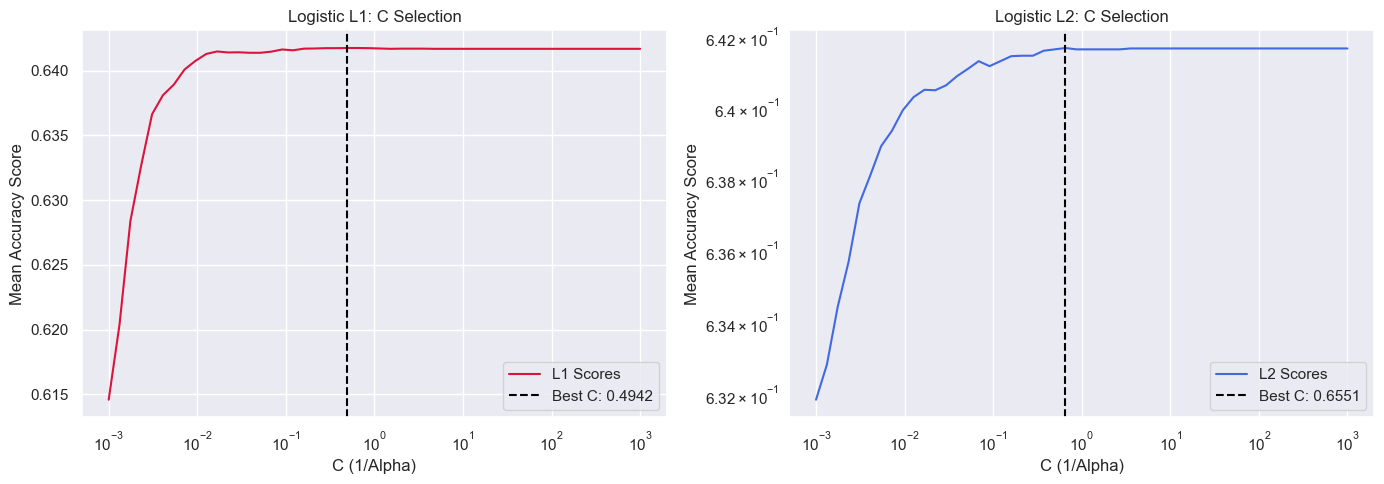


Logistic L1 accuracy: 0.6372  (AUC: 0.6785)
Logistic L2 accuracy: 0.6373  (AUC: 0.6785)

Logistic L1 status (threshold 1e-4):
Eliminated 0 features over 28
                     Feature  Coefficient  Abs_Coefficient Status
27                    m_wwbb    -1.021995         1.021995   Kept
26                     m_wbb     0.688168         0.688168   Kept
25                      m_bb    -0.607909         0.607909   Kept
5                     jet1pt     0.339931         0.339931   Kept
22                     m_jjj     0.268699         0.268699   Kept
3   missing_energy_magnitude    -0.230453         0.230453   Kept
24                     m_jlv     0.212316         0.212316   Kept
0                  lepton_pT    -0.181929         0.181929   Kept
21                      m_jj    -0.107271         0.107271   Kept
23                      m_lv     0.105661         0.105661   Kept


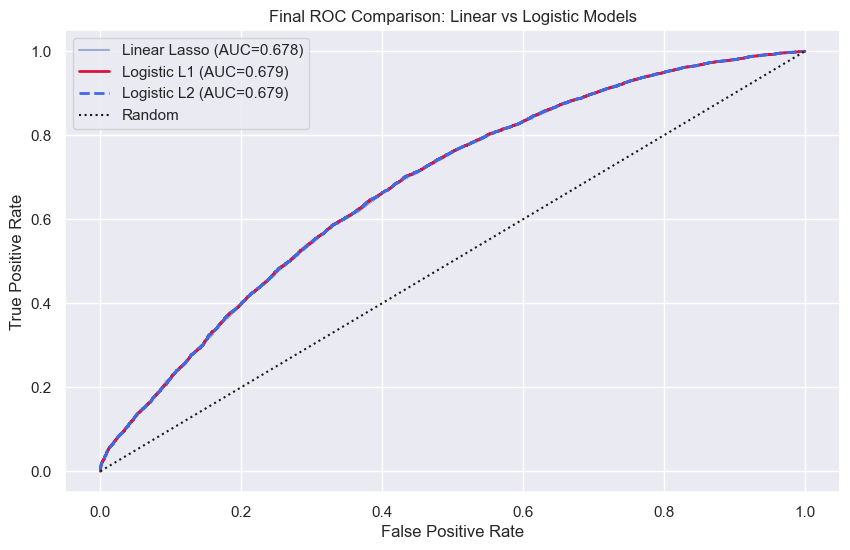

In [19]:
# BONUS 2: LOGISTIC REGRESSION with L1 (Lasso) and L2 (Ridge) penalty
# This is the correct approach for binary classification

Cs = np.logspace(-3, 3, 50)  # C = 1/alpha in sklearn convention

# --- TRAINING ---

# L1 Logistic (equivalent to Lasso but with log-loss)
logistic_l1 = LogisticRegressionCV(
    Cs=Cs, cv=kf, penalty='l1', solver='saga',
    max_iter=5000, random_state=42, n_jobs=-1
).fit(X_train, y_train)

# L2 Logistic (equivalent to Ridge but with log-loss)
logistic_l2 = LogisticRegressionCV(
    Cs=Cs, cv=kf, penalty='l2', solver='lbfgs',
    max_iter=5000, random_state=42, n_jobs=-1
).fit(X_train, y_train)

# --- PRINTS & COMPARISONS ---

print(f"Best C for Logistic L1: {logistic_l1.C_[0]:.5f}  (alpha = {1/logistic_l1.C_[0]:.5f})")
print(f"Best C for Logistic L2: {logistic_l2.C_[0]:.5f}  (alpha = {1/logistic_l2.C_[0]:.5f})")

# Calcolo Log-Loss media dai path di cross-validation
# Nota: LogisticRegressionCV memorizza i punteggi (accuratezza di default), 
# ma qui estraiamo l'andamento per visualizzare la scelta di C
l1_scores_mean = np.mean(logistic_l1.scores_[1], axis=0)
l2_scores_mean = np.mean(logistic_l2.scores_[1], axis=0)

# --- VISUALIZATION: ALPHA/C SELECTION ---

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.semilogx(logistic_l1.Cs_, l1_scores_mean, label='L1 Scores', color='crimson')
plt.axvline(logistic_l1.C_[0], color='black', linestyle='--', label=f'Best C: {logistic_l1.C_[0]:.4f}')
plt.xlabel('C (1/Alpha)')
plt.ylabel('Mean Accuracy Score')
plt.title('Logistic L1: C Selection')
plt.legend()

plt.subplot(1, 2, 2)
plt.loglog(logistic_l2.Cs_, l2_scores_mean, label='L2 Scores', color='royalblue')
plt.axvline(logistic_l2.C_[0], color='black', linestyle='--', label=f'Best C: {logistic_l2.C_[0]:.4f}')
plt.xlabel('C (1/Alpha)')
plt.ylabel('Mean Accuracy Score')
plt.title('Logistic L2: C Selection')
plt.legend()
plt.tight_layout()
plt.show()

# --- EVALUATION ON TEST SET ---

scores_l1 = logistic_l1.predict_proba(X_test)[:, 1]
scores_l2 = logistic_l2.predict_proba(X_test)[:, 1]

fpr_l1, tpr_l1, _ = roc_curve(y_test, scores_l1)
fpr_l2, tpr_l2, _ = roc_curve(y_test, scores_l2)
auc_l1 = auc(fpr_l1, tpr_l1)
auc_l2 = auc(fpr_l2, tpr_l2)

acc_l1 = accuracy_score(y_test, logistic_l1.predict(X_test))
acc_l2 = accuracy_score(y_test, logistic_l2.predict(X_test))

print(f"\nLogistic L1 accuracy: {acc_l1:.4f}  (AUC: {auc_l1:.4f})")
print(f"Logistic L2 accuracy: {acc_l2:.4f}  (AUC: {auc_l2:.4f})")

# --- FEATURE IMPORTANCE (L1) ---

log_l1_coefs = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': logistic_l1.coef_[0],
    'Abs_Coefficient': np.abs(logistic_l1.coef_[0]),
    'Status': np.where(np.abs(logistic_l1.coef_[0]) < 1e-4, 'Eliminated', 'Kept')
}).sort_values('Abs_Coefficient', ascending=False)

print(f"\nLogistic L1 status (threshold 1e-4):")
print(f"Eliminated {(log_l1_coefs['Status'] == 'Eliminated').sum()} features over {len(feature_names)}")
print(log_l1_coefs.head(10)) # Mostriamo le prime 10 per brevità

# --- ROC CURVE COMPARISON ---

plt.figure(figsize=(10, 6))
plt.plot(fpr_l,  tpr_l,  label=f'Linear Lasso (AUC={auc_lasso:.3f})', alpha=0.5)
plt.plot(fpr_l1, tpr_l1, label=f'Logistic L1 (AUC={auc_l1:.3f})', color='crimson', linewidth=2)
plt.plot(fpr_l2, tpr_l2, label=f'Logistic L2 (AUC={auc_l2:.3f})', color='royalblue', linestyle='--', linewidth=2)
plt.plot([0, 1], [0, 1], 'k:', label='Random')
plt.title("Final ROC Comparison: Linear vs Logistic Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [17]:
# TOP FEATURES COMPARISON across all methods
top_pca      = pca_analysis['Feature'].iloc[:3].tolist()
top_lasso    = lasso_coefs['Feature'].iloc[:3].tolist()
top_ridge    = ridge_coefs['Feature'].iloc[:3].tolist()
top_log_l1   = log_l1_coefs['Feature'].iloc[:3].tolist()
top_log_l2   = (pd.DataFrame({'Feature': feature_names, 'Abs': np.abs(logistic_l2.coef_[0])})
               .sort_values('Abs', ascending=False)['Feature'].iloc[:3].tolist())

print("=" * 65)
print("TOP 3 FEATURES BY METHOD:")
print(f"  PCA           (Unsupervised):  {', '.join(top_pca)}")
print(f"  Lasso/Linear  (L1, MSE):       {', '.join(top_lasso)}")
print(f"  Ridge/Linear  (L2, MSE):       {', '.join(top_ridge)}")
print(f"  Logistic      (L1, log-loss):  {', '.join(top_log_l1)}")
print(f"  Logistic      (L2, log-loss):  {', '.join(top_log_l2)}")
print("=" * 65)
print()
print("NOTE: PCA maximizes variance (unsupervised), not class separation.")
print("      Logistic regression uses log-loss, more appropriate for binary classification.")
print("      High-level features (m_bb, m_wwbb, m_jjj...) are expected to dominate in supervised models.")


TOP 3 FEATURES BY METHOD:
  PCA           (Unsupervised):  m_wbb, m_wwbb, m_jjj
  Lasso/Linear  (L1, MSE):       m_wwbb, m_wbb, m_bb
  Ridge/Linear  (L2, MSE):       m_wwbb, m_wbb, m_bb
  Logistic      (L1, log-loss):  m_wwbb, m_wbb, m_bb
  Logistic      (L2, log-loss):  m_wwbb, m_wbb, m_bb

NOTE: PCA maximizes variance (unsupervised), not class separation.
      Logistic regression uses log-loss, more appropriate for binary classification.
      High-level features (m_bb, m_wwbb, m_jjj...) are expected to dominate in supervised models.
